### **Unsupervised Learning - Data Center Archetypes**

Using multiple clustering models, we'll identify possible facility archetypes in the cleaned FracTracker dataset.

In [558]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [559]:
RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [560]:
# Load cleaned data
cleaned_data = pd.read_csv('./data/processed/fractracker_data_centers_clean.csv')

cleaned_data[['facility_name', 'state', 'sizerank', 'facility_size_sqft', 'property_size_acres']].head()

,facility_name,state,sizerank,facility_size_sqft,property_size_acres
0,Stak Energy Data Center,AK,"Mega campus (>1,000 MW)",NaN,715.00
1,Prudhoe Bay Data Center,AK,Hyperscale (100-999 MW),NaN,100.00
2,Project Marvel,AL,"Mega campus (>1,000 MW)","4,500,000.00","1,600.00"
3,BHM01 Nebius Data Center,AL,Hyperscale (100-999 MW),NaN,80.00
4,DC Blox,AL,Unknown,NaN,NaN


#### **Feature Availability**

There are a limited number of available features within our dataset. Even `sizerank`, a feature which looks complete, uses an 'Unknown' label for missing rows.

In [561]:
features = [
    'sizerank', 
    'facility_size_sqft', 
    'property_size_acres', 
    'project_cost', 
    'power_source',
    'cooling_source',
    'cooling_type'
]

availability = pd.DataFrame({
    'non_null':cleaned_data[features].notna().sum(),
    'percent_available':cleaned_data[features].notna().mean().mul(100).round(1)
})

availability.sort_values('percent_available', ascending=False)

,non_null,percent_available
sizerank,1708,100.00
facility_size_sqft,1034,60.50
property_size_acres,1022,59.80
project_cost,325,19.00
power_source,160,9.40
cooling_type,92,5.40
cooling_source,76,4.40


#### **Data Selection**

To maintain a large amount of the data sample while still ensuring there is enough data to analyze, the **facility** and **property** **sizes** are used to filter the dataset. This could introduce a selection bias in the results.

In [562]:
# Filter out any missing data rows
cleaned_data = cleaned_data.loc[
    (cleaned_data['facility_size_sqft'].notna())
    & (cleaned_data['property_size_acres'].notna())
]

print("Filtered Data: ", cleaned_data.shape)

Filtered Data:  (676, 85)


#### **Distribution of Capacity (Size Rank)**

Roughly 400 of the 676 values in the filtered dataset do not have a known capacity.

| Capacity | Numeric Value |
|---|---:|
| Unknown | 1 |
| Small (0–10 MW) | 2 |
| Medium (11–50 MW) | 3 |
| Large (51–99 MW) | 4 |
| Hyperscale (100–999 MW) | 5 |
| Mega campus (>1,000 MW) | 6 |

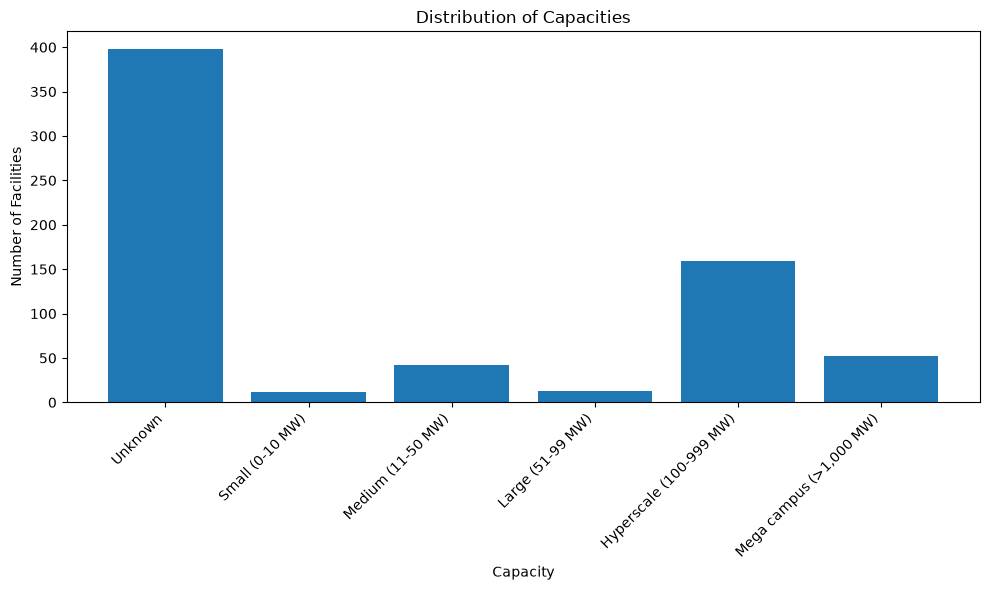

In [563]:
size_rank = {
    "Unknown": 1,
    "Small (0-10 MW)": 2,
    "Medium (11-50 MW)": 3,
    "Large (51-99 MW)": 4,
    "Hyperscale (100-999 MW)": 5,
    "Mega campus (>1,000 MW)": 6
}

# Arrange categories using capacity
size_counts = (
    cleaned_data["sizerank"]
    .value_counts()
    .reindex(size_rank.keys(), fill_value=0)
)

plt.figure(figsize=(10, 6))
plt.bar(size_counts.index, size_counts.values)

plt.title("Distribution of Capacities")
plt.xlabel("Capacity")
plt.ylabel("Number of Facilities")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### **Size Distributions**

This chart examines the distributions of facility size (square feet) and property size (acres) to better understand the variation in physical size across data centers. 

Both distributions are heavily right-skewed:
- Most data centers concentrated at smaller sizes
- A small number of exceptionally large facilities 

By capping values at the 99th percentile, we can reduce the visual impact of these extreme values and gain a clearer understanding of how most facilities are distributed.

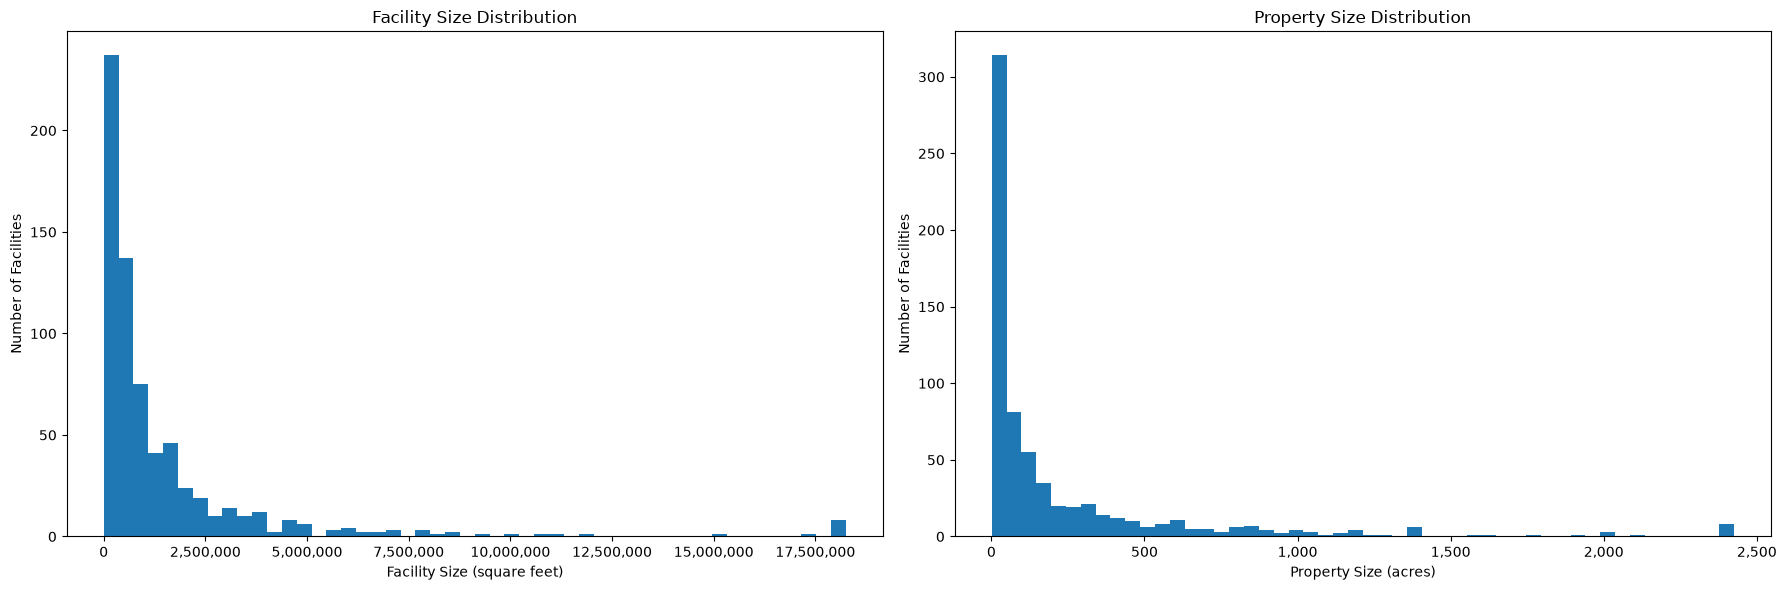

In [564]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].hist(
    cleaned_data["facility_size_sqft"].clip(
        upper=cleaned_data["facility_size_sqft"].quantile(0.99)
    ),
    bins=50
)
axes[0].set_title("Facility Size Distribution")
axes[0].set_xlabel("Facility Size (square feet)")
axes[0].set_ylabel("Number of Facilities")

axes[1].hist(
    cleaned_data["property_size_acres"].clip(
        upper=cleaned_data["property_size_acres"].quantile(0.99)
    ),
    bins=50
)
axes[1].set_title("Property Size Distribution")
axes[1].set_xlabel("Property Size (acres)")
axes[1].set_ylabel("Number of Facilities")

axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

plt.tight_layout()
plt.show()

#### **Correlation Matrix**

Spearman correlations reveal strong positive relationships among the listed features. This is unsurprising, as larger properties generally have larger facilities, which may also have greater power capacity (MW). However, this may limit the clustering analysis, as the features capture similar characteristics between data center types. More independent features could identify more meaningful patterns and help determine data center archetypes.

In [565]:
# Remove 'Unknown' data centers
corr_analysis = cleaned_data.loc[cleaned_data['sizerank_numeric'] != 1]

corr_analysis[['facility_size_sqft', 'property_size_acres', 'sizerank_numeric']].corr(method='spearman')

,facility_size_sqft,property_size_acres,sizerank_numeric
facility_size_sqft,1.00,0.77,0.72
property_size_acres,0.77,1.00,0.74
sizerank_numeric,0.72,0.74,1.00


#### **Feature Selection**

In [566]:
selected_features = [
    "sizerank_numeric",
    "facility_size_sqft",
    "property_size_acres"
]

cleaned_data = cleaned_data[selected_features]

# Scale all model features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cleaned_data)

#### **KMeans Clustering**

In [567]:
metrics = []

for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    clusters = kmeans.fit_predict(X_scaled)
    counts = np.bincount(clusters, minlength=k)
    
    metrics.append({
        'k': k, 
        'Silhouette': silhouette_score(X_scaled, clusters),
        'Davies Bouldin': davies_bouldin_score(X_scaled, clusters),
        'Smallest Cluster': counts.min(),
        'Largest Cluster': counts.max()
    })
    
metrics_df = pd.DataFrame(metrics)
metrics_df

,k,Silhouette,Davies Bouldin,Smallest Cluster,Largest Cluster
0,2,0.63,0.77,231,445
1,3,0.67,0.92,22,447
2,4,0.67,0.67,1,445
3,5,0.68,0.75,1,438
4,6,0.69,0.67,1,437
5,7,0.68,0.63,1,424


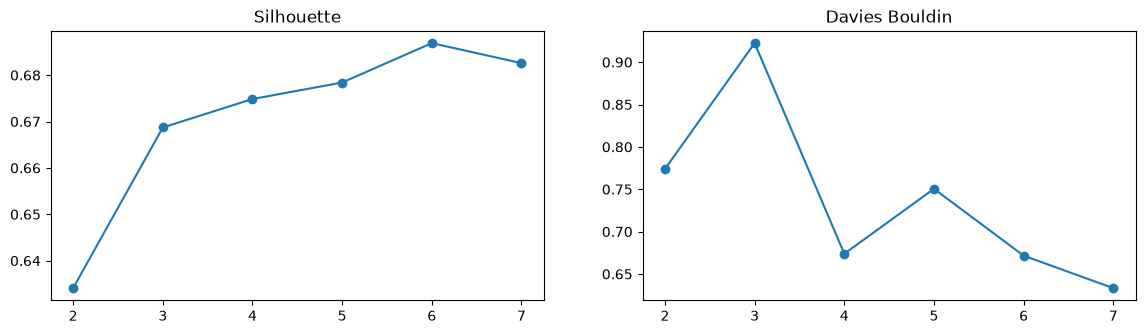

In [568]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))

metric_types = ['Silhouette', 'Davies Bouldin']

for ax, col in zip(axes, metric_types):
    ax.plot(metrics_df['k'], metrics_df[col], marker='o')
    ax.set_title(col)
    
plt.show()

#### **PCA Visualization** 

Based on the graphs above, we can determine an appropriate number of clusters (k) for the dataset. In this case, k = 4 appears to provide a reasonable balance between a low Davies-Bouldin score and a high Silhouette score, suggesting the clusters are reasonably well-separated. However, the cluster id = 3 seems to be only a single outlier value (may need to revisit data selection and remove outliers).

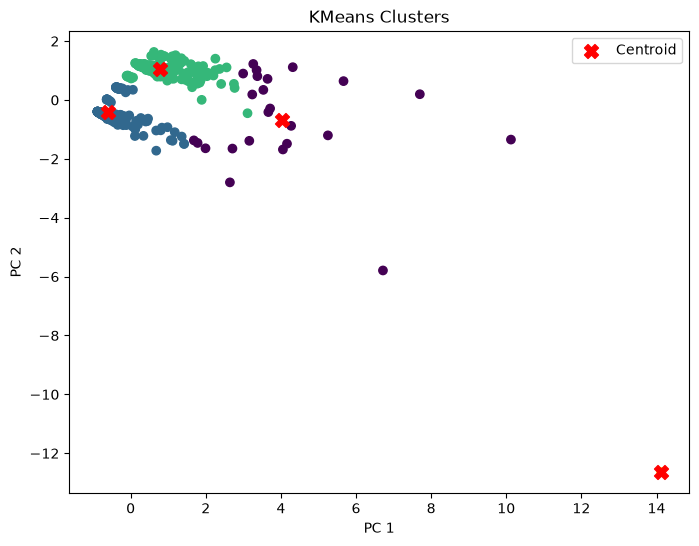

In [569]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
cleaned_data["km_cluster"] = kmeans.fit_predict(X_scaled)

# Reduce dimensions using PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cleaned_data["km_cluster"],
)

# Plot cluster centroids
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="red",
    marker="X",
    s=100,
    label="Centroid"
)

plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("KMeans Clusters")
plt.legend()
plt.show()

In [570]:
# Clusters
cleaned_data['km_cluster'].value_counts().to_frame()

,count
km_cluster,
1,445
2,206
0,24
3,1
